In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from datasets import load_dataset

In [ ]:
from datasets import load_dataset

emotion_dataset=load_dataset('dair-ai/emotion')
train_text=emotion_dataset['train']['text']
train_label=emotion_dataset['train']['label']

test_text=emotion_dataset['test']['text']
test_label=emotion_dataset['test']['label']
emotion_dataset
train_label

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Column([0, 0, 3, 2, 3, ...])

In [ ]:
label_names=emotion_dataset['train'].features['label'].names
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [ ]:
df_train=pd.DataFrame(
    {
        'text':train_text,
        'label':[label_names[i] for i in train_label]
    }

 )

df_test=pd.DataFrame(
    {
        'text':test_text,
        'label':[label_names[i] for i in test_label]
    }
)

In [ ]:
df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [ ]:
df_train.isnull().sum()

,0
text,0
label,0


<Axes: xlabel='label', ylabel='count'>

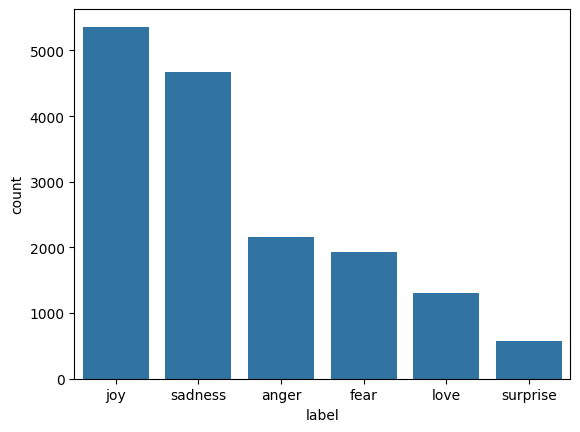

In [ ]:
sns.countplot(x='label',data=df_train,order=df_train['label'].value_counts().index)

In [ ]:
df_train['label'].value_counts()

,count
label,
joy,5362
sadness,4666
anger,2159
fear,1937
love,1304
surprise,572


In [ ]:
from IPython.testing import test
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words=1000

tokenizer=Tokenizer(num_words=max_words,oov_token='<unk>')
tokenizer.fit_on_texts(df_train['text'])

train_sequence=tokenizer.texts_to_sequences(df_train['text'])
test_sequence=tokenizer.texts_to_sequences(df_test['text'])


padded_train_sequence=pad_sequences(train_sequence,maxlen=50,padding='post',truncating='post')
padded_test_sequence=pad_sequences(test_sequence,maxlen=50,padding='post',truncating='post')


# padded_train_sequence

train_labels=np.array(train_label)
test_labels=np.array(test_label)

num_classes=len(np.unique(train_labels))
num_classes

print("Vocabulary Size:",len(tokenizer.word_index))
padded_train_sequence.shape
print("Max sentence length",(padded_train_sequence.shape[1]))

Vocabulary Size: 15213
Max sentence length 50


In [ ]:
from sklearn.utils import class_weight
class_weights=class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels

)

class_weight_dict=dict(enumerate(class_weights))

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
early_stopping=EarlyStopping(
    monitor='val_loss',
    patience=5,
    verbose=1,
    restore_best_weights=True
)

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN,Embedding,Dense,Dropout,LSTM,GRU
rnn_model=Sequential([
    Embedding(input_dim=max_words,output_dim=128),
    SimpleRNN(units=128,return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=num_classes,activation='softmax')
])
rnn_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])


In [ ]:
rnn_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence,test_labels),
    epochs=20,
    batch_size=32,

    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)
rnn_loss,rnn_accuracy=rnn_model.evaluate(padded_test_sequence,test_labels)
print("RNN Loss:",rnn_loss)
print("RNN Accuracy:",rnn_accuracy)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 28s 49ms/step - accuracy: 0.1638 - loss: 1.9594 - val_accuracy: 0.1670 - val_loss: 1.7901
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 28s 56ms/step - accuracy: 0.1637 - loss: 1.8134 - val_accuracy: 0.2650 - val_loss: 1.7748
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 56ms/step - accuracy: 0.1578 - loss: 1.7973 - val_accuracy: 0.2460 - val_loss: 1.7715
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 36s 46ms/step - accuracy: 0.1494 - loss: 1.7908 - val_accuracy: 0.1755 - val_loss: 1.7784
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 24s 47ms/step - accuracy: 0.1474 - loss: 1.8353 - val_accuracy: 0.0815 - val_loss: 1.8188
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 21s 41ms/step - accuracy: 0.1306 - loss: 1.8172 - val_accuracy: 0.1190 - val_loss: 1.7996
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 22s 44ms/step - accuracy: 0.1336 - loss: 1.8058 - val_accuracy: 0.0850 - val_loss: 1.8395
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 54s 71ms/step - accuracy: 0.1488 - loss: 1.8030 - 

In [ ]:
lstm_model=Sequential([
    Embedding(input_dim=max_words,output_dim=128),
    LSTM(units=128,return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes,activation='softmax')
])
lstm_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

lstm_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence,test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)
lstm_loss,lstm_accuracy=lstm_model.evaluate(padded_test_sequence,test_labels)
print("lstm Loss:",lstm_loss)
print("lstm Accuracy:",lstm_accuracy)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 69s 130ms/step - accuracy: 0.1447 - loss: 1.7946 - val_accuracy: 0.1210 - val_loss: 1.7852
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 165ms/step - accuracy: 0.1364 - loss: 1.7934 - val_accuracy: 0.1170 - val_loss: 1.7811
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 74s 149ms/step - accuracy: 0.1514 - loss: 1.7938 - val_accuracy: 0.1365 - val_loss: 1.7881
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 72s 128ms/step - accuracy: 0.1416 - loss: 1.7922 - val_accuracy: 0.0800 - val_loss: 1.8025
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 128ms/step - accuracy: 0.1523 - loss: 1.7907 - val_accuracy: 0.0385 - val_loss: 1.8177
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 1.
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.1210 - loss: 1.7852
lstm Loss: 1.7852013111114502
lstm Accuracy: 0.12099999934434891


In [ ]:
gru_model=Sequential([
    Embedding(input_dim=max_words,output_dim=128),
    GRU(units=128,return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes,activation='softmax')
])
gru_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

gru_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence,test_labels),
    epochs=20,
    batch_size=32,

    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)
gru_loss,gru_accuracy=gru_model.evaluate(padded_test_sequence,test_labels)
print("gru Loss:",gru_loss)
print("gru Accuracy:",gru_accuracy)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 57s 106ms/step - accuracy: 0.1484 - loss: 1.7959 - val_accuracy: 0.2875 - val_loss: 1.7841
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 53s 106ms/step - accuracy: 0.1583 - loss: 1.7959 - val_accuracy: 0.1120 - val_loss: 1.8089
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 52s 104ms/step - accuracy: 0.1486 - loss: 1.7937 - val_accuracy: 0.1065 - val_loss: 1.7914
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 52s 103ms/step - accuracy: 0.1514 - loss: 1.7945 - val_accuracy: 0.1390 - val_loss: 1.7763
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 83s 106ms/step - accuracy: 0.1588 - loss: 1.7922 - val_accuracy: 0.2745 - val_loss: 1.7911
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 1.
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.2875 - loss: 1.7841
gru Loss: 1.7840946912765503
gru Accuracy: 0.2874999940395355


In [ ]:
from tensorflow.keras.layers import Bidirectional
BIGRU=Sequential([
    Embedding(input_dim=max_words,output_dim=128),
    Bidirectional(GRU(units=128,return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(units=64)),
    Dropout(0.5),
    Dense(units=num_classes,activation='softmax')
])

BIGRU.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
BIGRU.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence,test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)
BIGRU_loss,BIGRU_accuracy=BIGRU.evaluate(padded_test_sequence,test_labels)
print("BIGRU Loss:",BIGRU_loss)
print("BIGRU Accuracy:",BIGRU_accuracy)


In [ ]:
from sklearn.metrics import confusion_matrix
BIGRU_predictions=BIGRU.predict(padded_test_sequence)
